In [43]:
import requests
import ast
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import csv


In [44]:
# Problem Encountered: HTTP Error 429, Too many requests
# Website blocks scraping and assumes we are a bot and immediately blocks us
# Use headers to trick website into thinking program is actually a browser, this effectively allows us to access the website and scrape it
url = "https://remoteok.com/remote-dev-jobs"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/112.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
}

src = requests.get(url, headers=headers)
soup = BeautifulSoup(src.content)
soup

<!DOCTYPE html>
<html class="pageType-tag remoteok minimize-header catch-emails-enabled" lang="en"> <head>
<link href="/global.css?1722013246" rel="stylesheet"/>
<script>
													var userIsAdmin=false;
											</script>
<meta charset="utf-8"/>
<title>Remote Developer Jobs with great benefits and pay</title>
<meta content="Browse 20+ Remote  Developer Jobs in April 2025 at companies like Sanctuary Computer, Revelator and Private.ki with salaries from $30,000/year to $150,000/year working as a React Native Developer, Intermediate Angular Developer or Senior Software Engineer. Last post 2 months" name="description"/>
<meta content="5E0F32F90CCE5417B26666C526F8B071" name="msvalidate.01">
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<meta content="en-US" http-equiv="Content-Language"/>
<link href="/opensearch.xml" rel="search" title="Remote OK" type="application/opensearchdescription+xml"/>
<meta name="google" value="notranslate"/>
<meta name="twitter:label1

In [45]:
listed_jobs = soup.find_all("tr", {"class":"job"})
print(listed_jobs)


[<tr class="job job-1093045 verified hot has-highlight-color dark =#ff4742=" data-company="Zammad" data-epoch="1745481148" data-href="/remote-jobs/remote-senior-full-stack-developer-zammad-1093045" data-id="1093045" data-offset="1" data-search="Zammad Senior Full Stack Developer [" data-slug="remote-senior-full-stack-developer-zammad-1093045" data-stack="" data-url="/remote-jobs/remote-senior-full-stack-developer-zammad-1093045" dev","full="" id="job-1093045" stack","full="" time"]"="" title="">
<td class="image has-logo" style="background-color:#ff4742;">
<script type="application/ld+json">
									{"@context":"http://schema.org","@type":"JobPosting","datePosted":"2025-04-24T07:52:28+00:00",
									"description":"<h2><a href=\"https:\/\/zammad.com\/en\/company\/jobs\/fullstack-developerza-what\">Za-What?<\/a><\/h2><p><strong>Zammad<\/strong>\u00a0is an open-source helpdesk platform with big ambitions to be the best of its kind. With technical founder Martin Edenhofer at the helm, Z

In [ ]:
# Problem Encountered: Not all data loaded; must scroll to scrape it
# Install Selenium and use it to launch a Chrome instance of the website
# Script runs and scrolls to the end then all data is loaded and we can now scrape all of it
# Store data in txt file to not run script every time

from selenium import webdriver
from selenium.webdriver.common.by import By

path_to_file = "W:/Loay/Python Projects/ToolsProject/"

driver = webdriver.Chrome()
driver.maximize_window()

driver.get(url)

last_height = 0

while True:
    driver.execute_script('window.scrollBy(0, 5000)')
    time.sleep(4)

    new_height = driver.execute_script("return document.body.scrollHeight")

    if(new_height == last_height):
        break

    else:
        last_height = new_height

page_source = driver.page_source

f = open(path_to_file+"source.txt","w",encoding="utf-8")
f.write(page_source)
f.close()

driver.close()

In [46]:
# Scrape html stored in txt file
import re
import numpy as np
from bs4 import BeautifulSoup

f = open(r"D:/ToolsProject/source.txt",'r',encoding='utf-8')
page_source = f.read()
f.close()
soup = BeautifulSoup(page_source)

#TODO: Get Job details and store in dictionary and convert it to csv file

listed_jobs = soup.find_all("tr", {"class":"job"})
df_roles = []
df_organizations = []
df_locations = []
df_time_posted = []
df_tags = []
df_expected_salary = np.zeros(len(listed_jobs), dtype='object')
for i in range(0, len(listed_jobs)):
    role = listed_jobs[i].find("h2").text.strip()
    organization = listed_jobs[i].find("h3").text.strip()
    html_location = listed_jobs[i].find_all("div", {"class": "location"})
    locations = []
    for j in html_location:
        if (str(j.contents)[2] == '💰'):
            salary_str = str(j.contents)
            salary_str = salary_str[4:-2]  # Clean string to get only salary part
            matches = re.findall(r'[0-9]{2,3}', salary_str)
            if len(matches) == 2:
                min_salary, max_salary = int(matches[0]), int(matches[1])
                avg_salary = min_salary + max_salary / 2.0
                df_expected_salary[i] = avg_salary
            elif len(matches) == 1:
                df_expected_salary[i] = int(matches[0])
            else:
                df_expected_salary[i] = None
        else:
            locations += j.contents

    locations = re.sub(r'<.*?>', r"", str(locations))
    html_time = listed_jobs[i].find("time")
    time_posted = re.sub(r'<.*?>', r'', (str(re.sub(r"[\t\n]", r"", str(html_time)))))
    html_tags = listed_jobs[i].find("td", {"class": "tags"}).find_all('h3')
    tags = [re.sub(r'<.*?>', r'', re.sub(r'[\s\t\n]', r'', str(i))) for i in html_tags]
    
    df_roles.append(role)
    df_organizations.append(organization)
    df_locations.append(locations)
    df_time_posted.append(time_posted)
    df_tags.append(tags)

data = {'Role':df_roles, 'Organization':df_organizations, 'Locations':df_locations, 'Time_Posted':df_time_posted, 'Tags':df_tags, 'Expected_Salary (*1000$)':df_expected_salary}
# Scraped 1033 listed jobs

In [47]:
import pandas as pd
df = pd.DataFrame(data)
df.to_csv('Scraped Data.csv')
df = pd.read_csv("D:/ToolsProject/Scraped Data.csv")
print(df)


      Unnamed: 0                                               Role  \
0              0                                      Web Developer   
1              1                  Senior React Full stack Developer   
2              2                           Administrative Executive   
3              3                                Full Stack Engineer   
4              4                  Internet of Things Technical Lead   
...          ...                                                ...   
1028        1028  Junior Full Stack Developer Complex Technical ...   
1029        1029   Sr Software Architect Engineer Node.js Meteor.js   
1030        1030                   Staff Software Engineer Accounts   
1031        1031                   Open Source Software Engineer Go   
1032        1032                           Senior Software Engineer   

              Organization                                          Locations  \
0                   Contra                    ['🌏 Worldwide', '⏰ C

In [48]:
df.head()

,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$)
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0


In [49]:
print(df.isnull().sum())

Unnamed: 0                   0
Role                         0
Organization                 0
Locations                    0
Time_Posted                  0
Tags                         0
Expected_Salary (*1000$)    63
dtype: int64


In [50]:
mean = df["Expected_Salary (*1000$)"].mean()
df["Expected_Salary (*1000$)"].fillna(mean, inplace = True)
df

C:\Users\ME\AppData\Local\Temp\ipykernel_22352\1693796763.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Expected_Salary (*1000$)"].fillna(mean, inplace = True)


,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$)
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0
...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,['🌏 Worldwide'],6yr,"['JavaScript', 'Meteor', 'Junior', 'FullStack'...",120.0
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"['🌏 Worldwide', 🇮🇳 India]",6yr,"['JavaScript', 'Meteor', 'Node', 'Engineer', '...",120.0
1030,1030,Staff Software Engineer Accounts,InVision,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Engineering']",122.5
1031,1031,Open Source Software Engineer Go,Datadog,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Go']",122.5


In [51]:
print(df.isnull().sum())

Unnamed: 0                  0
Role                        0
Organization                0
Locations                   0
Time_Posted                 0
Tags                        0
Expected_Salary (*1000$)    0
dtype: int64


In [10]:
df.head()

,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$)
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0


In [52]:
def parse_duration(x):
    if pd.isna(x):
        return np.nan #NaN
    num = int(''.join(filter(str.isdigit, x)))  
    unit = ''.join(filter(str.isalpha, x)).lower()  
    
    if unit == 'h':
        return pd.Timedelta(hours=num)
    elif unit == 'd':
        return pd.Timedelta(days=num)
    elif unit == 'mo':
        return pd.Timedelta(minutes=num)
    elif unit == 'yr':  
        return pd.Timedelta(days=num * 365)  
    else:
        return np.nan 

df['Time_Posted_parsed'] = df['Time_Posted'].apply(parse_duration)


now = pd.Timestamp.now()


df['Actual_Time'] = now - df['Time_Posted_parsed']


df['Actual_Time'] = df['Actual_Time'].dt.date


df


,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$),Time_Posted_parsed,Actual_Time
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0,0 days 22:00:00,2025-04-28
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0,1 days 00:00:00,2025-04-27
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0,4 days 00:00:00,2025-04-24
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0,15 days 00:00:00,2025-04-13
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0,10 days 00:00:00,2025-04-18
...,...,...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,['🌏 Worldwide'],6yr,"['JavaScript', 'Meteor', 'Junior', 'FullStack'...",120.0,2190 days 00:00:00,2019-04-30
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"['🌏 Worldwide', 🇮🇳 India]",6yr,"['JavaScript', 'Meteor', 'Node', 'Engineer', '...",120.0,2190 days 00:00:00,2019-04-30
1030,1030,Staff Software Engineer Accounts,InVision,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Engineering']",122.5,2190 days 00:00:00,2019-04-30
1031,1031,Open Source Software Engineer Go,Datadog,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Go']",122.5,2190 days 00:00:00,2019-04-30


In [53]:
df = df.drop("Time_Posted_parsed" , axis = 1)
df = df.drop("Time_Posted" , axis = 1)

In [54]:
df.rename(columns={'Actual_Time': 'Date_Posted'}, inplace=True)

df.head()

,Unnamed: 0,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']","['Other', 'Data', 'Consulting']",225.0,2025-04-28
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...","['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0,2025-04-27
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']","['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0,2025-04-24
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']","['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0,2025-04-13
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0,2025-04-18


In [55]:


df['Locations'] = df['Locations'].apply(
    lambda x: '['+ re.sub(r'[^\w\s,]', '', str(x).lstrip('[').rstrip(']')) + ']'
)
df['Locations'] = df['Locations'].str.replace(r'\s+', ' ', regex=True).str.strip()


df.head()
df


,Unnamed: 0,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,0,Web Developer,Contra,"[ Worldwide, Contractor]","['Other', 'Data', 'Consulting']",225.0,2025-04-28
1,1,Senior React Full stack Developer,Lemon.io,"[ Europe, Latin America, Australia, Canada, In...","['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0,2025-04-27
2,2,Administrative Executive,Prime Design & Build,"[ Latin America, Worldwide]","['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0,2025-04-24
3,3,Full Stack Engineer,Stealth,"[ Worldwide, Contractor]","['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0,2025-04-13
4,4,Internet of Things Technical Lead,Sanctuary Computer,[ Worldwide],"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0,2025-04-18
...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,[ Worldwide],"['JavaScript', 'Meteor', 'Junior', 'FullStack'...",120.0,2019-04-30
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"[ Worldwide, India]","['JavaScript', 'Meteor', 'Node', 'Engineer', '...",120.0,2019-04-30
1030,1030,Staff Software Engineer Accounts,InVision,[ Probably worldwide],"['Golang', 'Engineer', 'Engineering']",122.5,2019-04-30
1031,1031,Open Source Software Engineer Go,Datadog,[ Probably worldwide],"['Golang', 'Engineer', 'Go']",122.5,2019-04-30


In [83]:
print(df.duplicated().sum())

125


In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1033 entries, 0 to 1032
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                1033 non-null   int64  
 1   Role                      1033 non-null   object 
 2   Organization              1033 non-null   object 
 3   Locations                 1033 non-null   object 
 4   Tags                      1033 non-null   object 
 5   Expected_Salary (*1000$)  1033 non-null   float64
 6   Date_Posted               1033 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 56.6+ KB


In [56]:
df['Role'].unique()

array(['Web Developer', 'Senior React Full stack Developer',
       'Administrative Executive', 'Full Stack Engineer',
       'Internet of Things Technical Lead', 'Senior Software Engineer',
       'Javascript Fullstack Engineer Senior',
       'Full stack Ruby on Rails engineer Earn equity',
       'Full Stack Developer', 'Senior Mobile Developer',
       'Full Stack Web Developer',
       'Senior PHP Laravel Developer Full Stack', 'spoke person',
       'Senior Data Engineer', 'Sr Software Developer PHP MySQL',
       'React Native Developer', 'Intermediate Angular Developer',
       'Senior Software Engineer Backend', 'Developer',
       'Security & Risk Engineer US based', 'Full Stack React Engineer',
       'Front End lead developer', 'Backend Engineer',
       'Wordpress Developer', 'Software Engineer Backend',
       'Technical Support Engineer Developer', 'Senior Back End Wizard',
       'Principal Software Engineer', 'Product Marketing Manager',
       'Full stack Engineer PHP

In [57]:
df['Role'].nunique()

406

In [58]:
df['Role'].value_counts()

Role
Senior Software Engineer             131
Software Engineer                     52
Full Stack Developer                  29
Backend Developer                     25
Senior Go Developer                   23
                                    ... 
Software Engineer Ruby on Rails        1
Software Engineer Opportunity          1
Software Engineer Durable Objects      1
Experienced Symfony Developer          1
Open Source Software Engineer Go       1
Name: count, Length: 406, dtype: int64

In [59]:
import ast

def safe_parse(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]  
    return [x]

df['Tags'] = df['Tags'].apply(safe_parse)


In [60]:
# separates every single tag in the array 
df = df.explode('Tags')
print(df.explode('Tags'))


      Unnamed: 0                               Role Organization  \
0              0                      Web Developer       Contra   
0              0                      Web Developer       Contra   
0              0                      Web Developer       Contra   
1              1  Senior React Full stack Developer     Lemon.io   
1              1  Senior React Full stack Developer     Lemon.io   
...          ...                                ...          ...   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   

                                              Locations         Tags  \
0                              [ Worldwide, Contractor]        Other   
0                              [ Worldw

In [61]:
df['Tags'].unique()


array(['Other', 'Data', 'Consulting', 'Engineer', 'Senior', 'JavaScript',
       'FullStack', 'React', 'FullTime', 'Ruby', 'Python', 'Node',
       'English', 'Postgres', 'Typescript', 'AWS', 'Startup', 'Next',
       'Remote', 'iOS', 'SysAdmin', 'Design', 'Executive', 'Admin',
       'VirtualAssistant', 'NonTech', 'Pyton', 'Django', 'ReactNative',
       'Flutter', 'Android', 'Kotlin', 'CSS', 'GraphQL', 'GCP', 'Azure',
       'Software', 'FrontEnd', 'Training', 'Technical', 'UX', 'Code',
       'Web', 'Scrum', 'DevOps', 'Cloud', 'Microsoft', 'Mobile',
       'Management', 'Lead', 'Healthcare', 'Engineering', 'Backend',
       'Shopify', 'Mobiledev', 'API', 'PHP', 'Laravel', 'Tailwind',
       'Marketing', 'Sales', 'CustomerSupport', 'DataEngineer', 'SQL',
       'Angular', 'RubyonRails', 'Elixir', 'PythonDjango', 'NodeExpress',
       'Aosp', 'Rest', 'Crypto', 'Ethereum', 'System', 'Security',
       'Developer', 'Growth', 'Financial', 'Rails', 'Reliability', 'SaaS',
       'Test', 'T

In [73]:
df['Tags'].nunique()


232

In [63]:
df['Tags'].value_counts()


Tags
Golang          515
Engineer        510
Senior          487
JavaScript      353
Backend         300
               ... 
PythonDjango      1
Elixir            1
RubyonRails       1
DataEngineer      1
Product           1
Name: count, Length: 232, dtype: int64

In [71]:
def add_quotes_to_list_string(cell):
    if isinstance(cell, str):
        # Remove the brackets first
        cell = cell.strip('[]')
        # Split by comma
        items = [item.strip() for item in cell.split(',') if item.strip()]
        # Add quotes
        quoted_items = [f'"{item}"' for item in items]
        # Rebuild the string with brackets
        return '[' + ', '.join(quoted_items) + ']'
    else:
        return cell

df['Locations'] = df['Locations'].apply(add_quotes_to_list_string)


In [74]:
import ast

def safe_parse(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]  
    return [x]

df['Locations'] = df['Locations'].apply(safe_parse)

In [75]:
# separates every single tag in the array 
df = df.explode('Locations')
print(df.explode('Locations'))


      Unnamed: 0                      Role Organization           Locations  \
0              0             Web Developer       Contra           Worldwide   
0              0             Web Developer       Contra          Contractor   
0              0             Web Developer       Contra           Worldwide   
0              0             Web Developer       Contra          Contractor   
0              0             Web Developer       Contra           Worldwide   
...          ...                       ...          ...                 ...   
1032        1032  Senior Software Engineer      Netdata  Probably worldwide   
1032        1032  Senior Software Engineer      Netdata  Probably worldwide   
1032        1032  Senior Software Engineer      Netdata  Probably worldwide   
1032        1032  Senior Software Engineer      Netdata  Probably worldwide   
1032        1032  Senior Software Engineer      Netdata  Probably worldwide   

             Tags  Expected_Salary (*1000$) Date_Po

In [76]:
df['Locations'].unique()


array(['Worldwide', 'Contractor', 'Europe', 'Latin America', 'Australia',
       'Canada', 'Indonesia', 'New Zealand', 'Papua New Guinea',
       'Philippines', 'United Kingdom', 'United States',
       'Probably worldwide', 'Part time', 'South Africa', 'Minneapolis',
       'MN', 'India', 'Mumbai', 'North America', 'Spain', 'Poland',
       'Brazil', 'Middle East', 'Germany', nan, 'Canada Open to us',
       'Contract', 'Europe not just EU', 'Africa',
       'Canada East Canada Time Zones', 'Toronto', 'Ontario Canada', 'PT',
       'MT', 'CT', 'ET', 'UTC6', 'UTC7', 'Asia', 'European Timezone',
       'Morocco', 'Denmark', 'Czechia', 'Singapore', 'Malaysia', 'China',
       'Hong Kong', 'ANYWHERE IN EUROPE', 'Russia', 'Taiwan', 'Thailand',
       'Bulgaria', 'Based in European timezone between UTC1 and UTC3',
       'Remote between UTC3 and UTC3', 'Europe UTC1 to UTC3',
       'UTC1 German Timezone',
       'Remote position Full time WesternEastern Europe European Time Zone UTC1 to 3 o

In [77]:
df['Locations'].nunique()


59

In [78]:
df['Locations'].value_counts()


Locations
Worldwide                                                                                             2310
Probably worldwide                                                                                    1758
United States                                                                                         1125
Europe                                                                                                 842
Canada                                                                                                 416
Latin America                                                                                          285
North America                                                                                          284
United Kingdom                                                                                         173
Poland                                                                                                  50
Australia                  

In [80]:
df

,Unnamed: 0,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,0,Web Developer,Contra,Worldwide,Other,225.0,2025-04-28
0,0,Web Developer,Contra,Contractor,Other,225.0,2025-04-28
0,0,Web Developer,Contra,Worldwide,Data,225.0,2025-04-28
0,0,Web Developer,Contra,Contractor,Data,225.0,2025-04-28
0,0,Web Developer,Contra,Worldwide,Consulting,225.0,2025-04-28
...,...,...,...,...,...,...,...
1032,1032,Senior Software Engineer,Netdata,Probably worldwide,Senior,125.0,2019-04-30
1032,1032,Senior Software Engineer,Netdata,Probably worldwide,Golang,125.0,2019-04-30
1032,1032,Senior Software Engineer,Netdata,Probably worldwide,Engineer,125.0,2019-04-30
1032,1032,Senior Software Engineer,Netdata,Probably worldwide,Go,125.0,2019-04-30


C:\Users\ME\AppData\Local\Temp\ipykernel_22352\1207220290.py:9: UserWarning: Glyph 127798 (\N{HOT PEPPER}) missing from current font.
  plt.tight_layout()
C:\Users\ME\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127798 (\N{HOT PEPPER}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


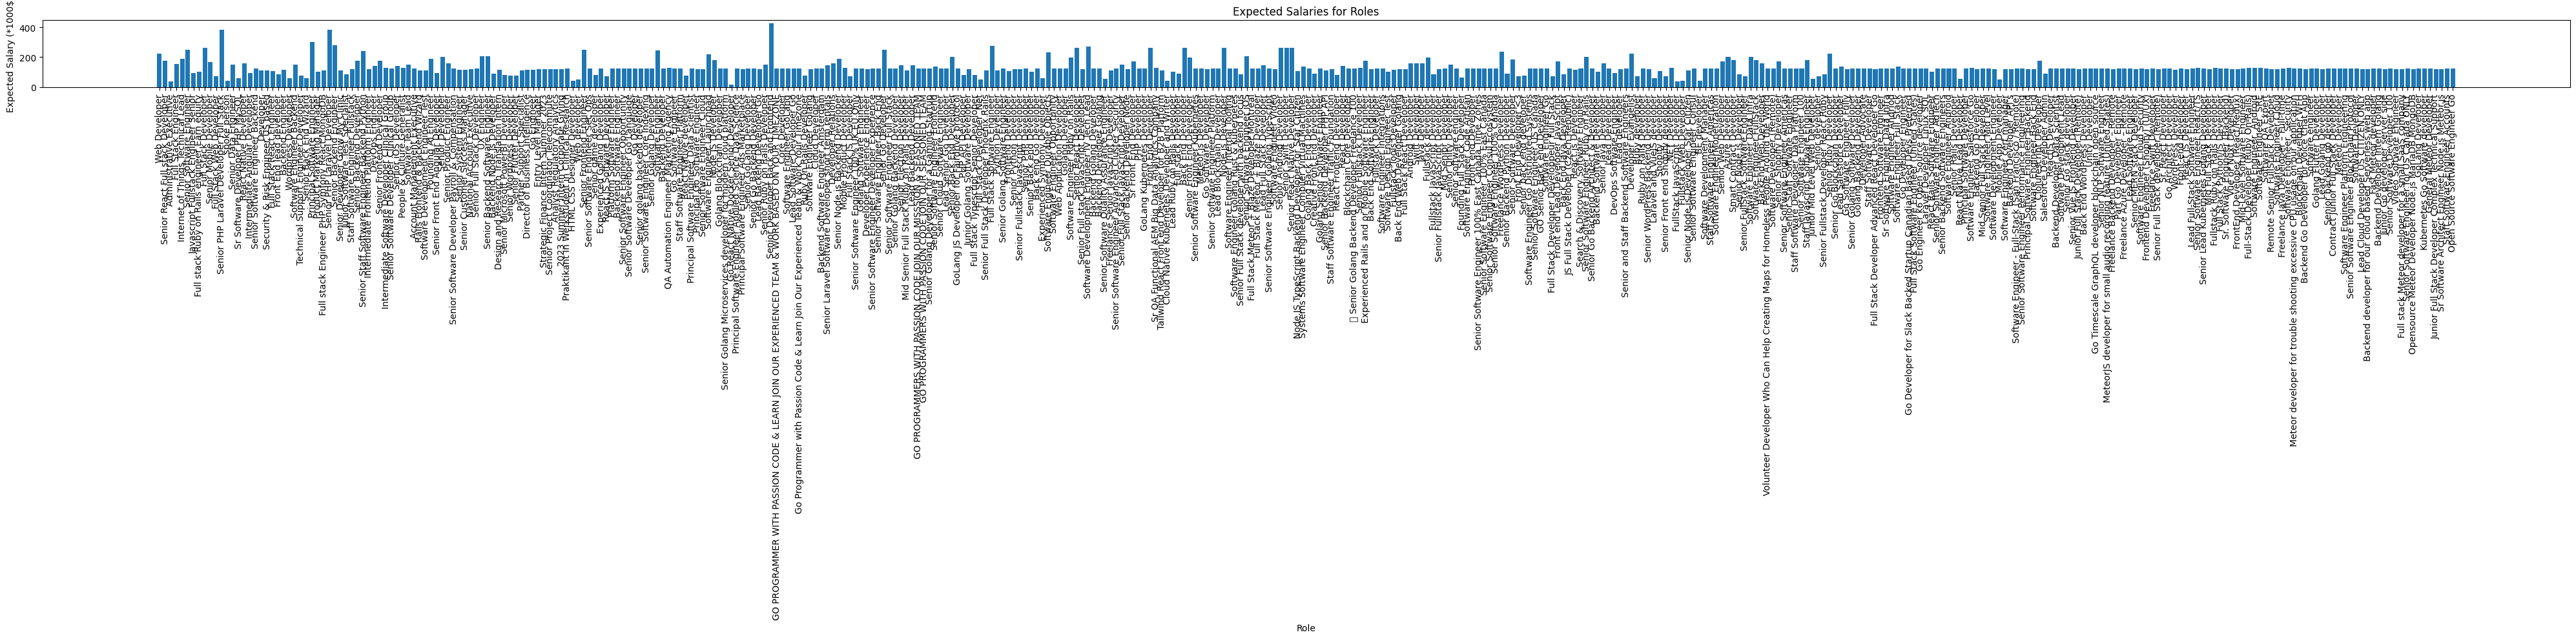

In [81]:
import matplotlib.pyplot as plt

plt.figure(figsize=(40, 10))  # ⬅️ Make it very wide
plt.bar(df['Role'], df['Expected_Salary (*1000$)'], width=0.8)  # Optional: width=bar thickness
plt.xlabel('Role')
plt.ylabel('Expected Salary (*1000$)')
plt.title('Expected Salaries for Roles')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
